>Implementar una función que calcule las componentes principales de un conjunto de datos a partir de su descomposici ́on en valores singulares (SVD). Para el calculo de las matrices de valores singulares pueden usar las bibliotecas y módulos ya conocidos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from numpy import ndarray

df = pd.read_csv('./europe.csv', delimiter=',')
df.head()

,Country,Area,GDP,Inflation,Life.expect,Military,Pop.growth,Unemployment
0,Austria,83871,41600,3.5,79.91,0.80,0.03,4.2
1,Belgium,30528,37800,3.5,79.65,1.30,0.06,7.2
2,Bulgaria,110879,13800,4.2,73.84,2.60,-0.80,9.6
3,Croatia,56594,18000,2.3,75.99,2.39,-0.09,17.7
4,Czech Republic,78867,27100,1.9,77.38,1.15,-0.13,8.5


In [2]:
id = 'Country'
features = list(set(df.columns) - {id})
X = df[features].to_numpy()

Voy a escalar el dataframe por comodidad. Podría no hacerlo y ver qué pasa

In [3]:
std_scale = StandardScaler()
std_scale.fit(X)
X_scaled = std_scale.transform(X)

algoritmo PCA:
* centrar X
* Hacer SVD
* Calcular varianza por componente  y varianza total
* Calcular proporción de varianza explicada por componente
* Truncar matrices
* Proyectar X centrado sobre matrices calculadas
* Devolver $X_{proyectado}$ en $q$ componentes, $V_q^t$ (matriz de $q$ componentes principales), array con cantidad de varianza explicada por componente

In [4]:
def pca_svd(X:ndarray, n_componentes:int|None=None):
    X_bar = np.mean(X, axis=0)
    X_centrado = X - X_bar
    N = X.shape[0]
    
    #obs: d es un array
    U, d, Vt = np.linalg.svd(X_centrado, full_matrices=False)

    #varianza explicada
    sigma_cuad = (d ** 2) / (N - 1)
    var_total = np.sum(sigma_cuad)
    varianza_explicada_ratio = sigma_cuad / var_total

    if n_componentes is None:
        n_componentes = X.shape[1]
    #truncar a las primeras q dimensiones
    U_q = U[:, :n_componentes]
    D_q = np.diag(d[:n_componentes])
    Vt_q = Vt[:n_componentes, :]
    
    #calcular los lambda_ij = U_q * D_q
    X_proyectado = np.dot(U_q, D_q)  
    #se podría calcular de la misma forma X_proyectado = X_centrado @ Vt_q.T

    return X_proyectado, Vt_q, varianza_explicada_ratio[:n_componentes]

X_proyectado, componentes, varianza_explicada = pca_svd(X_scaled)

Grafiquitos ↓

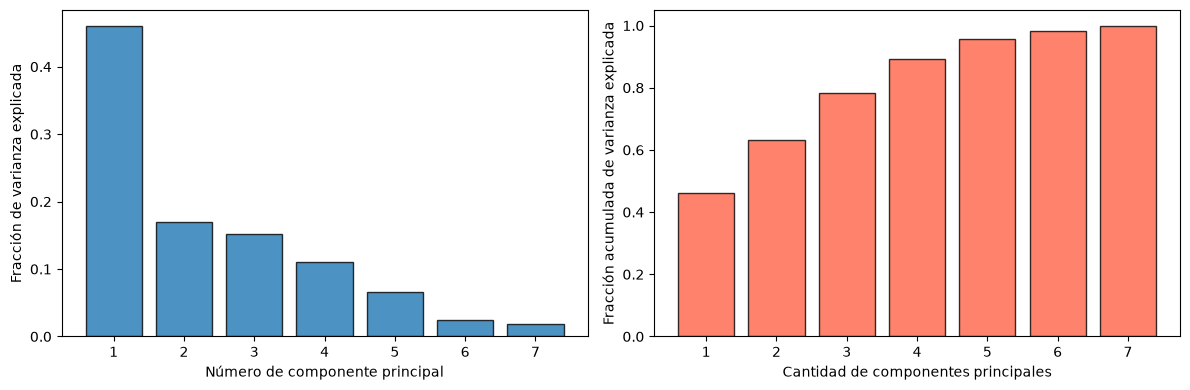

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Eje X común (número de componentes)
n_componentes = range(1, len(varianza_explicada) + 1)

# 1. Gráfico de varianza explicada individual
ax[0].bar(n_componentes, varianza_explicada, edgecolor='black', alpha=0.8)
ax[0].set_ylabel('Fracción de varianza explicada')
ax[0].set_xlabel('Número de componente principal')
ax[0].set_xticks(n_componentes) # Para asegurar que muestre cada número entero

# Varianza acumulada
varianza_acumulada = np.cumsum(varianza_explicada)

# 2. Gráfico de varianza acumulada
ax[1].bar(n_componentes, varianza_acumulada, color = 'tomato',edgecolor='black', alpha=0.8)
ax[1].set_ylabel('Fracción acumulada de varianza explicada')
ax[1].set_xlabel('Cantidad de componentes principales')
ax[1].set_xticks(n_componentes)

plt.tight_layout()
plt.show()

Composición de las componentes en función de las features originales

In [6]:
componentes_df = pd.DataFrame(
    [[round(float(a), 3) for a in componentes[0]],
     [round(float(a), 3) for a in componentes[1]],
     [round(float(a), 3) for a in componentes[2]],
     [round(float(a), 3) for a in componentes[4]]],
    columns=features,
    index=['Comp. Principal 1', 'Comp. Principal 2','Comp. Principal 3','Comp. Principal 4']
)
componentes_df

,Unemployment,Inflation,Military,Pop.growth,Area,Life.expect,GDP
Comp. Principal 1,-0.272,-0.407,-0.188,0.476,-0.125,0.483,0.501
Comp. Principal 2,0.553,-0.370,0.658,0.083,-0.173,0.265,-0.130
Comp. Principal 3,-0.001,-0.198,-0.244,-0.164,-0.898,-0.246,-0.084
Comp. Principal 4,-0.010,-0.690,-0.368,-0.348,0.324,0.102,-0.391


Proyeccion de features en el espacio de componentes principales

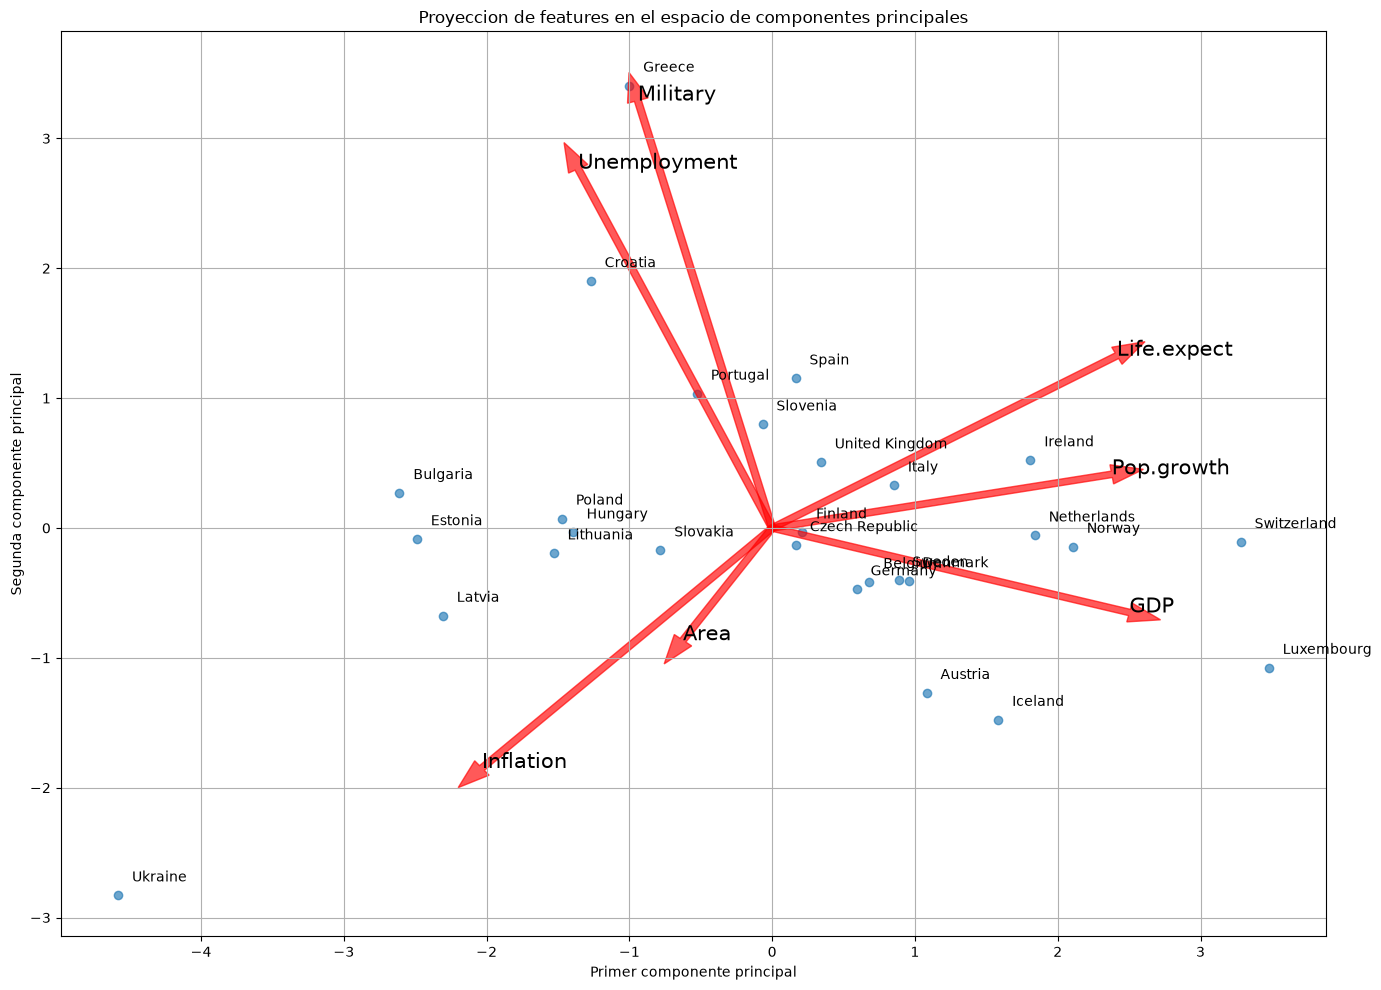

In [7]:
fig, ax = plt.subplots(figsize = (14, 10))
plt.grid()
plt.title('Proyeccion de features en el espacio de componentes principales')
for i, row in df.iterrows():
  pais = row[id]
  ax.annotate(pais, (X_proyectado[i,0],X_proyectado[i,1]), xytext=(10,10), textcoords='offset points')

ax.scatter(X_proyectado[:,0], X_proyectado[:,1], alpha = 0.65)
escala = 5
for i in range(len(features)):

  # Creamos una flecha que vaya del origen y apunte en la dirección de los features
  ax.arrow(0, 0, escala * componentes[0][i], escala * componentes[1][i], width = 0.05, color = 'r', alpha = 0.65)

  # Indicamos con texto a qué feature corresponde cada flecha
  ax.text(escala * componentes[0][i], escala * componentes[1][i], s = features[i], fontdict= {'color': 'k', 'size': 15})
ax.set_xlabel('Primer componente principal')
ax.set_ylabel('Segunda componente principal')
plt.tight_layout()
plt.show()